<a href="https://colab.research.google.com/github/PixelPixe/Skin-Lesion-Segmentation-and-Classification-using-Deep-Learning/blob/main/DENSENET121_different_parameters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import os

ZIP_PATH = "/content/HAM10000_segmented.zip"
EXTRACT_PATH = "/content/HAM10000_segmented"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Done")

Done


In [ ]:
print(len(os.listdir(EXTRACT_PATH)))

10015


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000


In [ ]:
import pandas as pd

HAM_PATH = "/kaggle/input/skin-cancer-mnist-ham10000"

metadata = pd.read_csv(
    f"{HAM_PATH}/HAM10000_metadata.csv"
)

In [ ]:
metadata['segmented_path'] = metadata['image_id'].apply(
    lambda x: os.path.join(
        EXTRACT_PATH,
        x + ".jpg"
    )
)

In [ ]:
print(metadata['segmented_path'].iloc[0])
print(os.path.exists(metadata['segmented_path'].iloc[0]))

/content/HAM10000_segmented/ISIC_0027419.jpg
True


In [ ]:
df = metadata[
    metadata['dx'].isin(['mel','nv'])
].copy()

df['target'] = (
    df['dx'] == 'mel'
).astype(int)

In [ ]:
mel_df = df[df['target']==1]
nv_df = df[df['target']==0]

nv_sample = nv_df.sample(
    n=len(mel_df),
    random_state=42
)

balanced_df = pd.concat(
    [mel_df, nv_sample]
).sample(frac=1, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    balanced_df,
    test_size=0.2,
    stratify=balanced_df['target'],
    random_state=42
)

In [ ]:
print(train_df['target'].value_counts())
print(test_df['target'].value_counts())

target
1    890
0    890
Name: count, dtype: int64
target
1    223
0    223
Name: count, dtype: int64


In [ ]:
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)

test_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
BATCH_SIZE = 32
CLS_SIZE = 224

train_generator = train_gen.flow_from_dataframe(
    train_df,
    x_col='segmented_path',
    y_col='target',
    target_size=(CLS_SIZE, CLS_SIZE),
    class_mode='raw',
    batch_size=BATCH_SIZE
)

test_generator = test_gen.flow_from_dataframe(
    test_df,
    x_col='segmented_path',
    y_col='target',
    target_size=(CLS_SIZE, CLS_SIZE),
    class_mode='raw',
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 1780 validated image filenames.
Found 446 validated image filenames.


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import BatchNormalization
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable = True

for layer in base_model.layers[:-90]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = True

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)

output = Dense(
    1,
    activation='sigmoid'
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,304,257 (27.86 MB)

 Trainable params: 2,022,273 (7.71 MB)

 Non-trainable params: 5,281,984 (20.15 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['target']),
    y=train_df['target']
)

class_weights = {
    0: class_weights[0],
    1: class_weights[1]
}

print(class_weights)

{0: np.float64(1.0), 1: np.float64(1.0)}


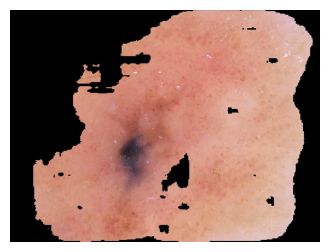

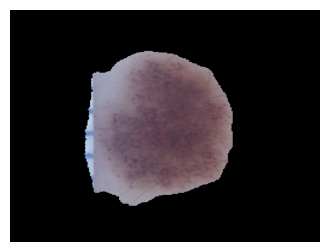

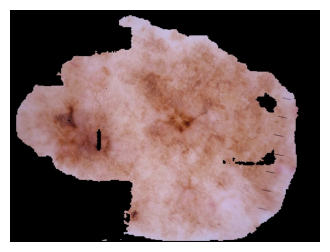

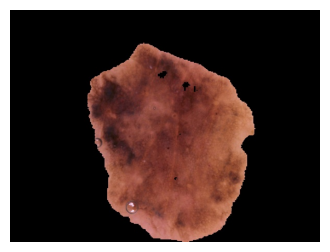

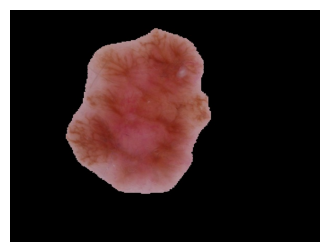

In [ ]:
import matplotlib.pyplot as plt
import cv2
import random

for i in range(5):
    idx = random.randint(0, len(train_df)-1)

    img = cv2.imread(train_df.iloc[idx]['segmented_path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import AUC

model.compile(
    optimizer=Adam(1e-5),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        AUC(name='auc')
    ]
)

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(
    monitor='val_auc',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        'best_densenet121.keras',
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_auc',
        mode='max',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
history = model.fit(
    train_generator,
    validation_data=test_generator,   # use val_generator if available
    epochs=40,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 903ms/step - accuracy: 0.5170 - auc: 0.5405 - loss: 0.7849
Epoch 1: val_auc improved from None to 0.76580, saving model to best_densenet121.keras

Epoch 1: finished saving model to best_densenet121.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.5635 - auc: 0.6070 - loss: 0.7276 - val_accuracy: 0.6659 - val_auc: 0.7658 - val_loss: 0.6254 - learning_rate: 1.0000e-05
Epoch 2/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.6904 - auc: 0.7606 - loss: 0.5896
Epoch 2: val_auc improved from 0.76580 to 0.83938, saving model to best_densenet121.keras

Epoch 2: finished saving model to best_densenet121.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 525ms/step - accuracy: 0.6910 - auc: 0.7648 - loss: 0.5870 - val_accuracy: 0.7108 - val_auc: 0.8394 - val_loss: 0.5277 - learning_rate: 1.0000e-05
Epoch 3/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.7587 - auc: 0.8303 - loss: 0.5107
Epoch 3: val_auc improved from 0.83938 to 0.86210, sa

In [ ]:
from tensorflow.keras.models import load_model

best_model = load_model("best_densenet121.keras")

In [ ]:
print(metadata['dx'].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
metadata['target'] = metadata['dx'].apply(
    lambda x: 1 if x == 'mel' else 0
)

print(metadata['target'].value_counts())

target
0    8902
1    1113
Name: count, dtype: int64


In [ ]:
pred_probs = model.predict(test_generator)

print("Min:", pred_probs.min())
print("Max:", pred_probs.max())
print("Mean:", pred_probs.mean())

14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step
Min: 1.5111527e-05
Max: 0.99893373
Mean: 0.49875948


In [ ]:
pred_probs = best_model.predict(test_generator)

preds = (pred_probs > 0.5).astype(int)

14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_df['target'],
        preds
    )
)

              precision    recall  f1-score   support

           0       0.89      0.79      0.84       223
           1       0.81      0.90      0.85       223

    accuracy                           0.85       446
   macro avg       0.85      0.85      0.84       446
weighted avg       0.85      0.85      0.84       446



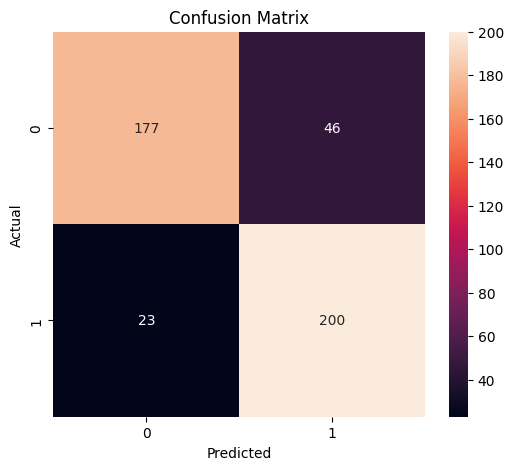

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    test_df['target'],
    preds
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

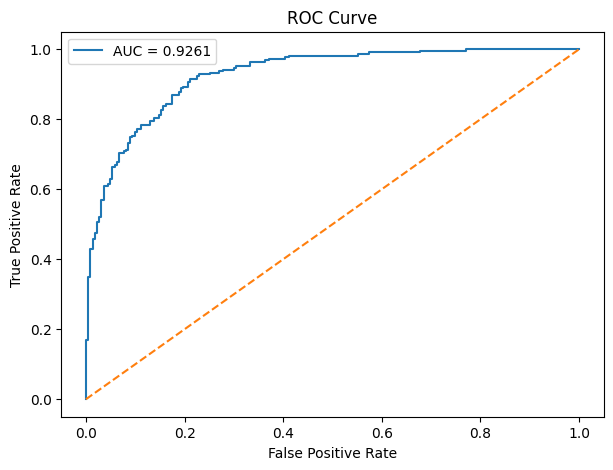

AUC: 0.9261195680588791


In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(
    test_df['target'],
    pred_probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

print("AUC:", roc_auc)

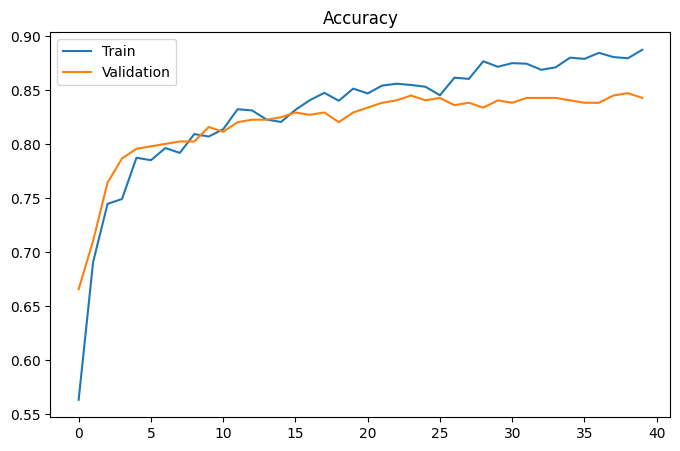

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.title('Accuracy')
plt.savefig('accuracy.png')
plt.show()

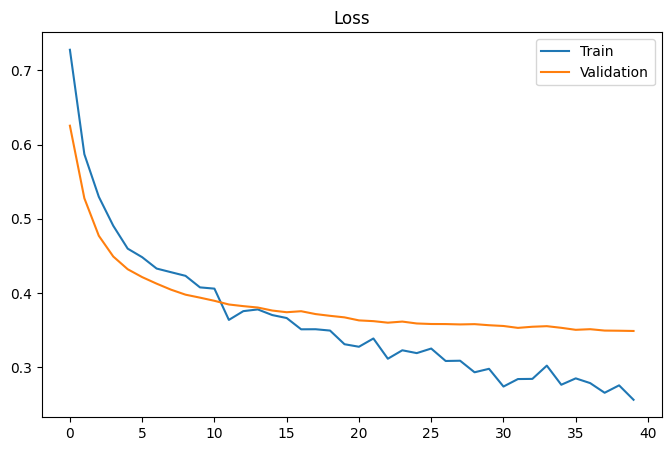

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.title('Loss')
plt.savefig('loss.png')
plt.show()